In [3]:
import matplotlib.pyplot as plt
import seaborn as sns 
import pandas as pd
import numpy as np

df1 = pd.read_csv('Unemployment_in_India.csv')
df2 = pd.read_csv('Unemployment_Rate_upto_11_2020.csv')

df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

print('=== DATASET 1 AUDIT (May 2019 - Jun 2020) ===')
print(f'Raw Shape: {df1.shape}')
print(f'Completely Empty Rows: {df1.isnull().all(axis=1).sum()}')

# Drop the 28 empty trailing rows and parse dates
df1_clean = df1.dropna().copy()
df1_clean['Date'] = pd.to_datetime(
    df1_clean['Date'].str.strip(), dayfirst=True
)
df1_clean['Area'] = df1_clean['Area'].str.strip()
df1_clean['Region'] = df1_clean['Region'].str.strip()

print(f'Clean Shape: {df1_clean.shape}\n')

print('=== DATASET 2 AUDIT (Jan 2020 - Oct 2020) ===')
print(f'Raw Shape: {df2.shape}')
print(f'Missing Values: {df2.isnull().sum().sum()}')

df2_clean = df2.copy()
df2_clean.rename(columns={'Region.1': 'Zone'}, inplace=True)
df2_clean['Date'] = pd.to_datetime(
    df2_clean['Date'].str.strip(), dayfirst=True
)
df2_clean['Month'] = df2_clean['Date'].dt.month
df2_clean['Region'] = df2_clean['Region'].str.strip()
df2_clean['Zone'] = df2_clean['Zone'].str.strip()

=== DATASET 1 AUDIT (May 2019 - Jun 2020) ===
Raw Shape: (768, 7)
Completely Empty Rows: 28
Clean Shape: (740, 7)

=== DATASET 2 AUDIT (Jan 2020 - Oct 2020) ===
Raw Shape: (267, 9)
Missing Values: 0


In [4]:

# 2. PRE-LOCKDOWN VS. LOCKDOWN SHOCK ANALYSIs
df1_clean['Period'] = np.where(
    df1_clean['Date'] < '2020-04-01',
    'Pre-Lockdown (May 2019 - Mar 2020)',
    'Lockdown Shock (Apr - Jun 2020)',
)

print('\n=== IMPACT OF COVID-19 LOCKDOWN (DATASET 1) ===')
period_summary = (
    df1_clean.groupby('Period')[[
        'Estimated Unemployment Rate (%)',
        'Estimated Labour Participation Rate (%)',
        'Estimated Employed',
    ]]
    .agg(['mean', 'median', 'max'])
    .round(2)
)
print(period_summary)

print('\n=== URBAN VS. RURAL BREAKDOWN BY PERIOD ===')
area_summary = (
    df1_clean.groupby(['Period', 'Area'])['Estimated Unemployment Rate (%)']
    .agg(['mean', 'median', 'max'])
    .round(2)
)
print(area_summary)


=== IMPACT OF COVID-19 LOCKDOWN (DATASET 1) ===
                                   Estimated Unemployment Rate (%)         \
                                                              mean median   
Period                                                                      
Lockdown Shock (Apr - Jun 2020)                              20.19  16.40   
Pre-Lockdown (May 2019 - Mar 2020)                            9.61   7.22   

                                           \
                                      max   
Period                                      
Lockdown Shock (Apr - Jun 2020)     76.74   
Pre-Lockdown (May 2019 - Mar 2020)  34.69   

                                   Estimated Labour Participation Rate (%)  \
                                                                      mean   
Period                                                                       
Lockdown Shock (Apr - Jun 2020)                                      38.05   
Pre-Lockdown (May 2019 - Ma

In [5]:
# 3. 2020 MONTHLY TRAJECTORY & STATE RANKINGS

print('\n=== 2020 MONTHLY NATIONAL AVERAGES (DATASET 2) ===')
monthly_2020 = (
    df2_clean.groupby('Date')[[
        'Estimated Unemployment Rate (%)',
        'Estimated Labour Participation Rate (%)',
        'Estimated Employed',
    ]]
    .mean()
    .round(2)
)
print(monthly_2020)

print('\n=== TOP 10 STATES BY AVERAGE UNEMPLOYMENT RATE (2020) ===')
state_rankings = (
    df2_clean.groupby(['Region', 'Zone'])['Estimated Unemployment Rate (%)']
    .agg(Avg_Unemployment_Pct='mean', Peak_Unemployment_Pct='max')
    .sort_values(by='Avg_Unemployment_Pct', ascending=False)
    .round(2)
)
print(state_rankings.head(10))


=== 2020 MONTHLY NATIONAL AVERAGES (DATASET 2) ===
            Estimated Unemployment Rate (%)  \
Date                                          
2020-01-31                             9.20   
2020-02-29                             9.27   
2020-03-31                            10.78   
2020-04-30                            22.24   
2020-05-31                            23.24   
2020-06-30                            10.91   
2020-07-31                             9.83   
2020-08-31                            10.31   
2020-09-30                             8.71   
2020-10-31                             8.03   

            Estimated Labour Participation Rate (%)  Estimated Employed  
Date                                                                     
2020-01-31                                    44.63         15637199.77  
2020-02-29                                    44.18         15488266.04  
2020-03-31                                    43.75         14538659.89  
2020-04-30   

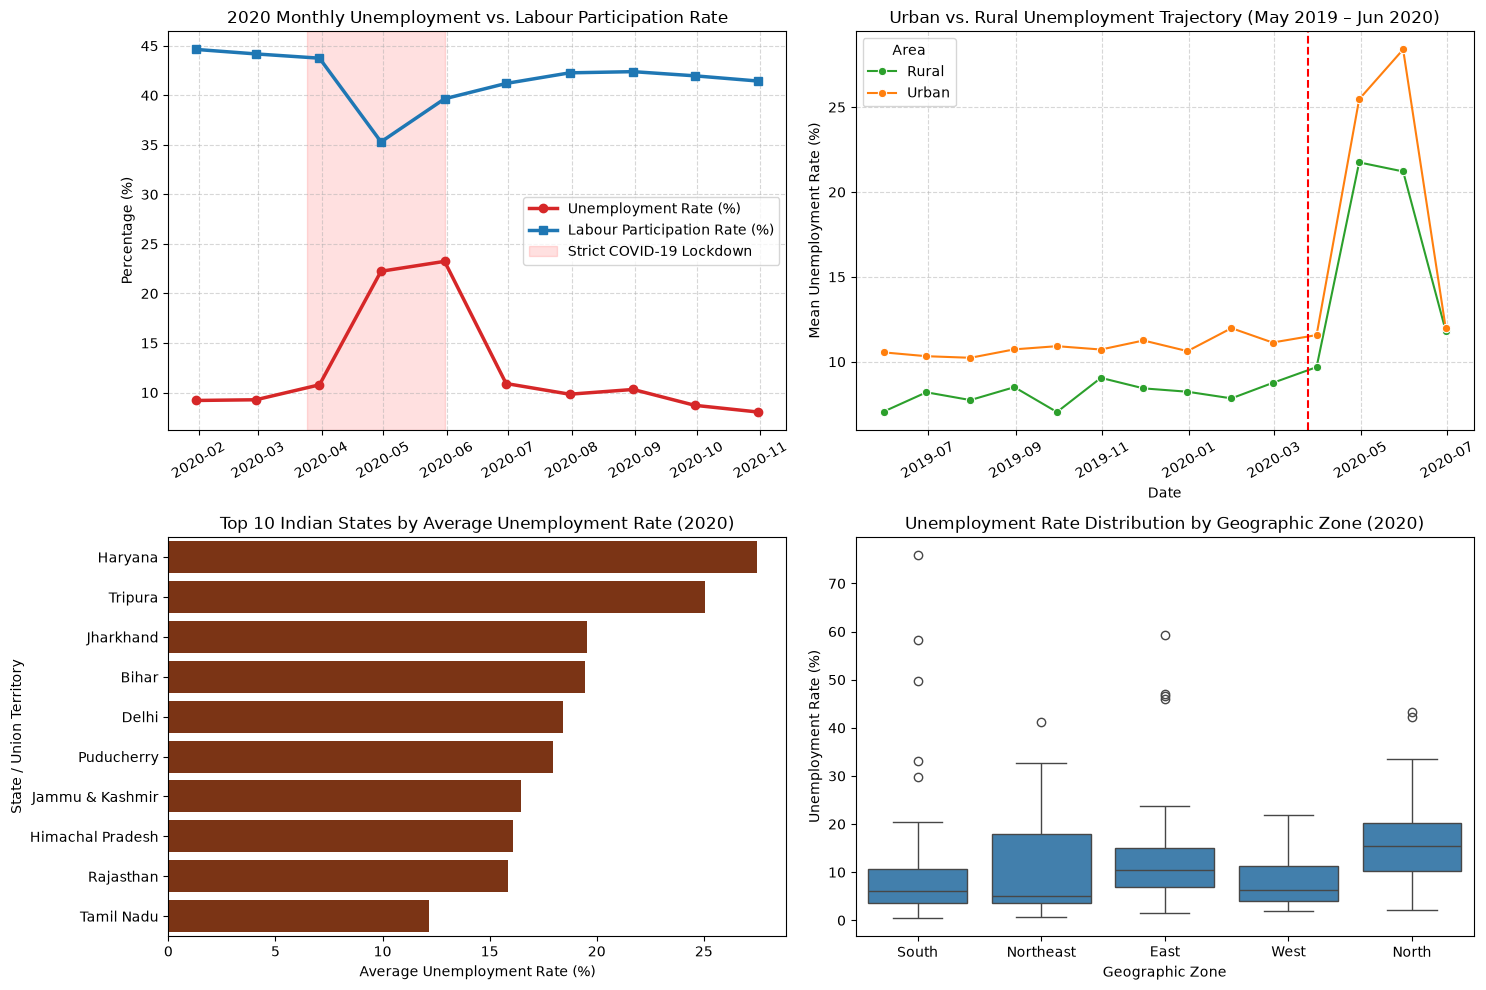

In [6]:
# 4. VISUALIZATIONS (4-PANEL EXECUTIVE DASHBOARD)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Panel 1: 2020 Monthly Unemployment vs. Labour Participation Rate
m_trend = monthly_2020.reset_index()
axes[0, 0].plot(
    m_trend['Date'],
    m_trend['Estimated Unemployment Rate (%)'],
    marker='o',
    color='#d62728',
    linewidth=2.5,
    label='Unemployment Rate (%)',
)
axes[0, 0].plot(
    m_trend['Date'],
    m_trend['Estimated Labour Participation Rate (%)'],
    marker='s',
    color='#1f77b4',
    linewidth=2.5,
    label='Labour Participation Rate (%)',
)
axes[0, 0].axvspan(
    pd.to_datetime('2020-03-25'),
    pd.to_datetime('2020-05-31'),
    color='red',
    alpha=0.12,
    label='Strict COVID-19 Lockdown',
)
axes[0, 0].set_title('2020 Monthly Unemployment vs. Labour Participation Rate')
axes[0, 0].set_ylabel('Percentage (%)')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].legend(loc='best')
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Urban vs. Rural Trajectory (May 2019 - Jun 2020)
area_trend = (
    df1_clean.groupby(['Date', 'Area'])['Estimated Unemployment Rate (%)']
    .mean()
    .reset_index()
)
sns.lineplot(
    data=area_trend,
    x='Date',
    y='Estimated Unemployment Rate (%)',
    hue='Area',
    marker='o',
    palette=['#2ca02c', '#ff7f0e'],
    ax=axes[0, 1],
)
axes[0, 1].axvline(
    pd.to_datetime('2020-03-25'),
    color='red',
    linestyle='--',
    label='National Lockdown',
)
axes[0, 1].set_title(
    'Urban vs. Rural Unemployment Trajectory (May 2019 – Jun 2020)'
)
axes[0, 1].set_ylabel('Mean Unemployment Rate (%)')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: Top 10 States by Average 2020 Unemployment Rate
top10_states = state_rankings['Avg_Unemployment_Pct'].head(10)
sns.barplot(
    x=top10_states.values, y=top10_states.index.get_level_values(0), color='#8c2d04', ax=axes[1, 0]
)
axes[1, 0].set_title('Top 10 Indian States by Average Unemployment Rate (2020)')
axes[1, 0].set_xlabel('Average Unemployment Rate (%)')
axes[1, 0].set_ylabel('State / Union Territory')

# Panel 4: Regional Zone Distribution
sns.boxplot(
    data=df2_clean,
    x='Zone',
    y='Estimated Unemployment Rate (%)',
    color='#3182bd',
    ax=axes[1, 1],
)
axes[1, 1].set_title('Unemployment Rate Distribution by Geographic Zone (2020)')
axes[1, 1].set_xlabel('Geographic Zone')
axes[1, 1].set_ylabel('Unemployment Rate (%)')

plt.tight_layout()
plt.show()